In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import PandasTools
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [129]:
delaney_df= pd.read_csv('data/delaney.csv')
delaney_df.columns

Index(['Compound ID', 'logS', 'smiles'], dtype='str')

In [130]:
ecoli_mics_df= pd.read_csv('data/ecoli_mics_sample.csv')
ecoli_mics_df.columns

Index(['chembl_id', 'smiles', 'mic', 'unit'], dtype='str')

In [131]:
print(delaney_df.shape)
print(ecoli_mics_df.shape)

(1144, 3)
(1100, 4)


In [132]:
for x in ecoli_mics_df.columns:
    print(x, ecoli_mics_df[x].value_counts(dropna=False))

chembl_id chembl_id
CHEMBL8          23
CHEMBL44354      16
CHEMBL702        15
CHEMBL148        13
CHEMBL174        13
                 ..
CHEMBL3818944     1
CHEMBL523325      1
CHEMBL309805      1
CHEMBL403         1
CHEMBL6461        1
Name: count, Length: 888, dtype: int64
smiles smiles
O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O                                                  23
CC(C)(O/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(C[n+]3ccccc3)CS[C@H]12)c1csc(N)n1)C(=O)O    16
CCN1CCN(C(=O)N[C@@H](C(=O)N[C@@H]2C(=O)N3[C@@H]2SC(C)(C)[C@@H]3C(=O)O)c2ccccc2)C(=O)C1=O    15
C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C@H]12                                         13
CC1(C)S[C@@H]2[C@H](NC(=O)[C@H](N)c3ccccc3)C(=O)N2[C@H]1C(=O)O                              13
                                                                                            ..
O=[N+]([O-])c1cccc(C2C3=C(N=C4SC=C(c5ccc(Cl)cc5)N42)c2ccccc2SC3)c1                           1
CSc1ccc(Cc2nnc3sc(-c4ccc(-c5cc(Cl)ccc5Cl)o

In [133]:
for x in delaney_df.columns:
    print(x, delaney_df[x].value_counts(dropna=False))

Compound ID Compound ID
3-Methyl-2-pentanol          2
1,1,1,2-Tetrachloroethane    1
1,1,1-Trichloroethane        1
1,1,2,2-Tetrachloroethane    1
1,1,2-Trichloroethane        1
                            ..
vamidothion                  1
Vinclozolin                  1
Warfarin                     1
Xipamide                     1
XMC                          1
Name: count, Length: 1143, dtype: int64
logS logS
-1.960    7
-1.600    6
-2.680    6
-1.300    6
-0.850    6
         ..
 1.144    1
-4.925    1
-3.893    1
-3.790    1
-2.581    1
Name: count, Length: 743, dtype: int64
smiles smiles
Clc1ccc(cc1)c2cccc(Cl)c2Cl                     2
Clc1ccc(cc1)c2cc(Cl)ccc2Cl                     2
Clc1ccc(cc1)c2ccccc2Cl                         2
CCC(C)CCO                                      2
CCOC(=O)c1ccc(N)cc1                            2
                                              ..
CNC(=O)C(C)SCCSP(=O)(OC)(OC)                   1
CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C          1
CC(=O)CC

In [134]:
print(delaney_df.columns)
print(ecoli_mics_df.columns)

Index(['Compound ID', 'logS', 'smiles'], dtype='str')
Index(['chembl_id', 'smiles', 'mic', 'unit'], dtype='str')


In [135]:
ecoli_mics_df.isnull().sum()

chembl_id    0
smiles       0
mic          2
unit         0
dtype: int64

In [136]:
ecoli_cleaned= ecoli_mics_df[~ecoli_mics_df['mic'].isna()]
ecoli_cleaned.shape

(1098, 4)

In [137]:
# for image column for datasets from smiles column
def column_smiles_to_image(df,smiles_column, image_column):
    PandasTools.AddMoleculeColumnToFrame(df, smilesCol=smiles_column, molCol=image_column)
    PandasTools.RenderImagesInAllDataFrames(images=True)
    return df

In [138]:
motifs = [('aromatic_c_O','cO'), 
          ('aliphatic_N','N'),
          ('alcohol', '[OH]'),
          ('benzene', 'c1ccccc1'),
          ('sulphur_ring', '[S;R]'),
          ('O_in_ring', '[O;R]'),
          ('ether', '[#6][OX2][#6]'),
          ('carboxylic', '[CX3](=O)[OX2H1]'),
          ('pyridine', 'c1ccncc1'),
          ('halogen', '[F,Cl,Br,I]'),
          ('amide', '[CX3](=O)[NX3]'),
          ('ketone', '[#6][CX3](=O)[#6]'),
          ('aldehyde', '[CX3H1](=O)[#6]'),
          ('alkene', '[CX3]=[CX3]'),     
          ('alkyne', '[CX2]#[CX2]')]

def custom_fp(motifs,df, smiles_column):
    for name, smarts in motifs:
        df[name] = df[smiles_column].apply(lambda smi: int(Chem.MolFromSmiles(smi).HasSubstructMatch(Chem.MolFromSmarts(smarts))))
    motif_names = [name for name, _ in motifs]
    df['fingerprint'] = df[motif_names].values.tolist()
    return df

In [139]:
def morgan_fp(df, smiles_column):
    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    df["morgan_fp"] = df[smiles_column].apply(lambda smi: morgan_gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(smi)))
    return df

In [140]:
Descriptors.CalcMolDescriptors(delaney_df['smiles'][0])

{'MaxAbsEStateIndex': None,
 'MaxEStateIndex': None,
 'MinAbsEStateIndex': None,
 'MinEStateIndex': None,
 'qed': None,
 'SPS': None,
 'MolWt': None,
 'HeavyAtomMolWt': None,
 'ExactMolWt': None,
 'NumValenceElectrons': None,
 'NumRadicalElectrons': None,
 'MaxPartialCharge': None,
 'MinPartialCharge': None,
 'MaxAbsPartialCharge': None,
 'MinAbsPartialCharge': None,
 'FpDensityMorgan1': None,
 'FpDensityMorgan2': None,
 'FpDensityMorgan3': None,
 'BCUT2D_MWHI': nan,
 'BCUT2D_MWLOW': nan,
 'BCUT2D_CHGHI': nan,
 'BCUT2D_CHGLO': nan,
 'BCUT2D_LOGPHI': nan,
 'BCUT2D_LOGPLOW': nan,
 'BCUT2D_MRHI': nan,
 'BCUT2D_MRLOW': nan,
 'AvgIpc': None,
 'BalabanJ': None,
 'BertzCT': None,
 'Chi0': None,
 'Chi0n': None,
 'Chi0v': None,
 'Chi1': None,
 'Chi1n': None,
 'Chi1v': None,
 'Chi2n': None,
 'Chi2v': None,
 'Chi3n': None,
 'Chi3v': None,
 'Chi4n': None,
 'Chi4v': None,
 'HallKierAlpha': None,
 'Ipc': None,
 'Kappa1': None,
 'Kappa2': None,
 'Kappa3': None,
 'LabuteASA': None,
 'PEOE_VSA1': None,

In [141]:
def decriptor_calc(df, smiles_column):
    desc_df= pd.DataFrame([Descriptors.CalcMolDescriptors(Chem.MolFromSmiles(smi)) for smi in df[smiles_column]],
    index=df.index,)
    return desc_df

In [146]:
# Target

def rf_result(df,target_column,desc_df,testsize,randomstate,nestimators):
    y = df[target_column].values

    # Feature sets as matrices (rows = molecules, columns = features)
    X_custom = np.array(df["fingerprint"].tolist())     # custom SMARTS fingerprint
    X_morgan = np.vstack(df["morgan_fp"])                # Morgan 
    # One split of row indices, shared by all feature sets, so the comparison is fair
    idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=testsize, random_state=randomstate)
    
    corr_train = desc_df.iloc[idx_train].corrwith(pd.Series(y[idx_train], index=desc_df.index[idx_train]))
    top30 = corr_train.abs().sort_values(ascending=False).head(30).index.tolist()

    print(top30)
    X_descr = desc_df[top30].values  # RDKit descriptors

    # Check the shapes line up
    for name, X in [("custom", X_custom), ("morgan", X_morgan), ("descr", X_descr)]:
        print(name, X.shape, "| y:", y.shape)

    feature_sets = {
        "Custom fingerprint": X_custom,
        "Morgan fingerprint": X_morgan,
        "RDKit descriptors":  X_descr,
    }

    
    results = []
    for name, X in feature_sets.items():
        rf = RandomForestRegressor(n_estimators=nestimators, random_state=42)
        rf.fit(X[idx_train], y[idx_train])
        pred_train = rf.predict(X[idx_train])
        pred_test  = rf.predict(X[idx_test])
        results.append({
            "Feature set": name,
            "n_features": X.shape[1],
            "Train R2": r2_score(y[idx_train], pred_train),
            "Test R2":  r2_score(y[idx_test], pred_test),
            "Test RMSE": mean_squared_error(y[idx_test], pred_test) ** 0.5,
            "Test MAE":  mean_absolute_error(y[idx_test], pred_test),
        })

    return pd.DataFrame(results).set_index("Feature set").round(3)

delaney dataset

,Compound ID,logS,smiles,molecule_image,aromatic_c_O,aliphatic_N,alcohol,benzene,sulphur_ring,O_in_ring,...,carboxylic,pyridine,halogen,amide,ketone,aldehyde,alkene,alkyne,fingerprint,morgan_fp
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl,,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl,,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl,,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl,,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl,,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."

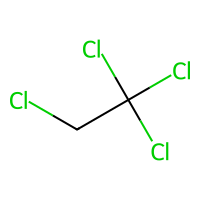
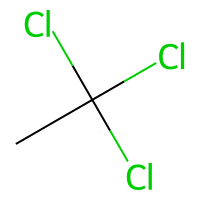
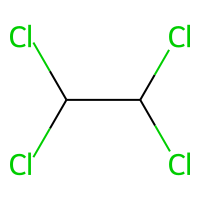
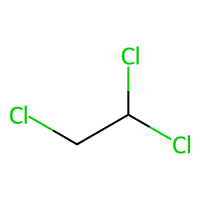
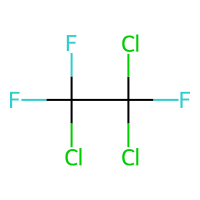

In [143]:
delaney_df= column_smiles_to_image(delaney_df, 'smiles', 'molecule_image')
delaney_df=custom_fp(motifs, delaney_df, 'smiles')
delaney_df= morgan_fp(delaney_df, 'smiles')
delaney_df.head()

In [144]:
desc_df_delaney= decriptor_calc(delaney_df, 'smiles')
desc_df_delaney.head()


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,5.116512,5.116512,0.039352,-1.276235,0.487138,12.00,167.850,165.834,165.891061,38,...,0,0,0,0,0,0,0,0,0,0
1,5.060957,5.060957,1.083333,-1.083333,0.445171,12.00,133.405,130.381,131.930033,32,...,0,0,0,0,0,0,0,0,0,0
2,5.114198,5.114198,0.672840,-0.672840,0.527312,11.00,167.850,165.834,165.891061,38,...,0,0,0,0,0,0,0,0,0,0
3,5.095679,5.095679,0.308642,-0.405864,0.480258,9.60,133.405,130.381,131.930033,32,...,0,0,0,0,0,0,0,0,0,0
4,11.544753,11.544753,3.685957,-4.226080,0.553756,14.25,187.375,187.375,185.901768,50,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# choosing important features from the descriptor set based on correlation values with the target
y = delaney_df["logS"]

# Pearson (linear) and Spearman (monotonic) correlation of each descriptor with the target
corr = pd.DataFrame({
    "pearson":  desc_df_delaney.corrwith(y, method="pearson"),
    "spearman": desc_df_delaney.corrwith(y, method="spearman"),
}).dropna()

# Rank by absolute Pearson correlation
corr = corr.reindex(corr["pearson"].abs().sort_values(ascending=False).index)
print(corr.head(15).round(3))

c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


                  pearson  spearman
MolLogP            -0.828    -0.845
PEOE_VSA6          -0.706    -0.628
MolMR              -0.698    -0.742
LabuteASA          -0.653    -0.703
Chi0v              -0.653    -0.715
MolWt              -0.637    -0.676
HeavyAtomMolWt     -0.637    -0.666
ExactMolWt         -0.636    -0.675
Chi1v              -0.633    -0.719
FpDensityMorgan1    0.600     0.550
BCUT2D_LOGPHI      -0.593    -0.637
Chi1               -0.588    -0.644
BertzCT            -0.588    -0.600
Chi2v              -0.587    -0.702
HeavyAtomCount     -0.582    -0.640


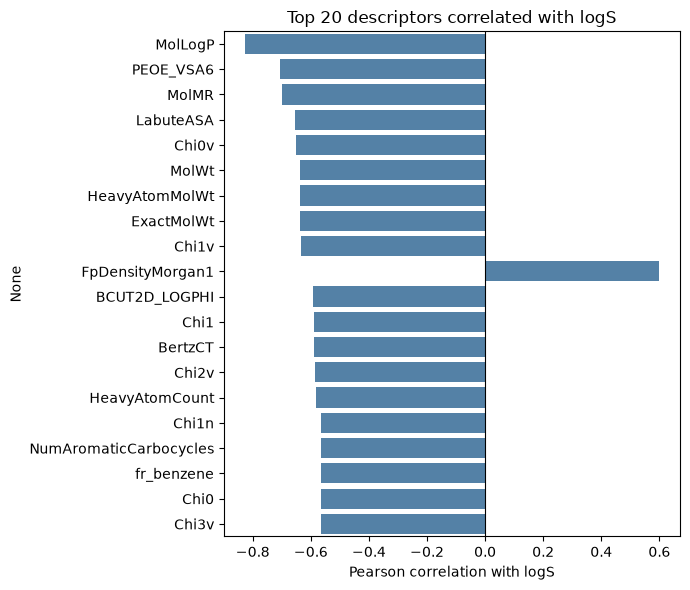

In [153]:
top = corr.head(20)
plt.figure(figsize=(7, 6))
sns.barplot(x=top["pearson"], y=top.index, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with logS")
plt.title("Top 20 descriptors correlated with logS")
plt.tight_layout()
plt.show()

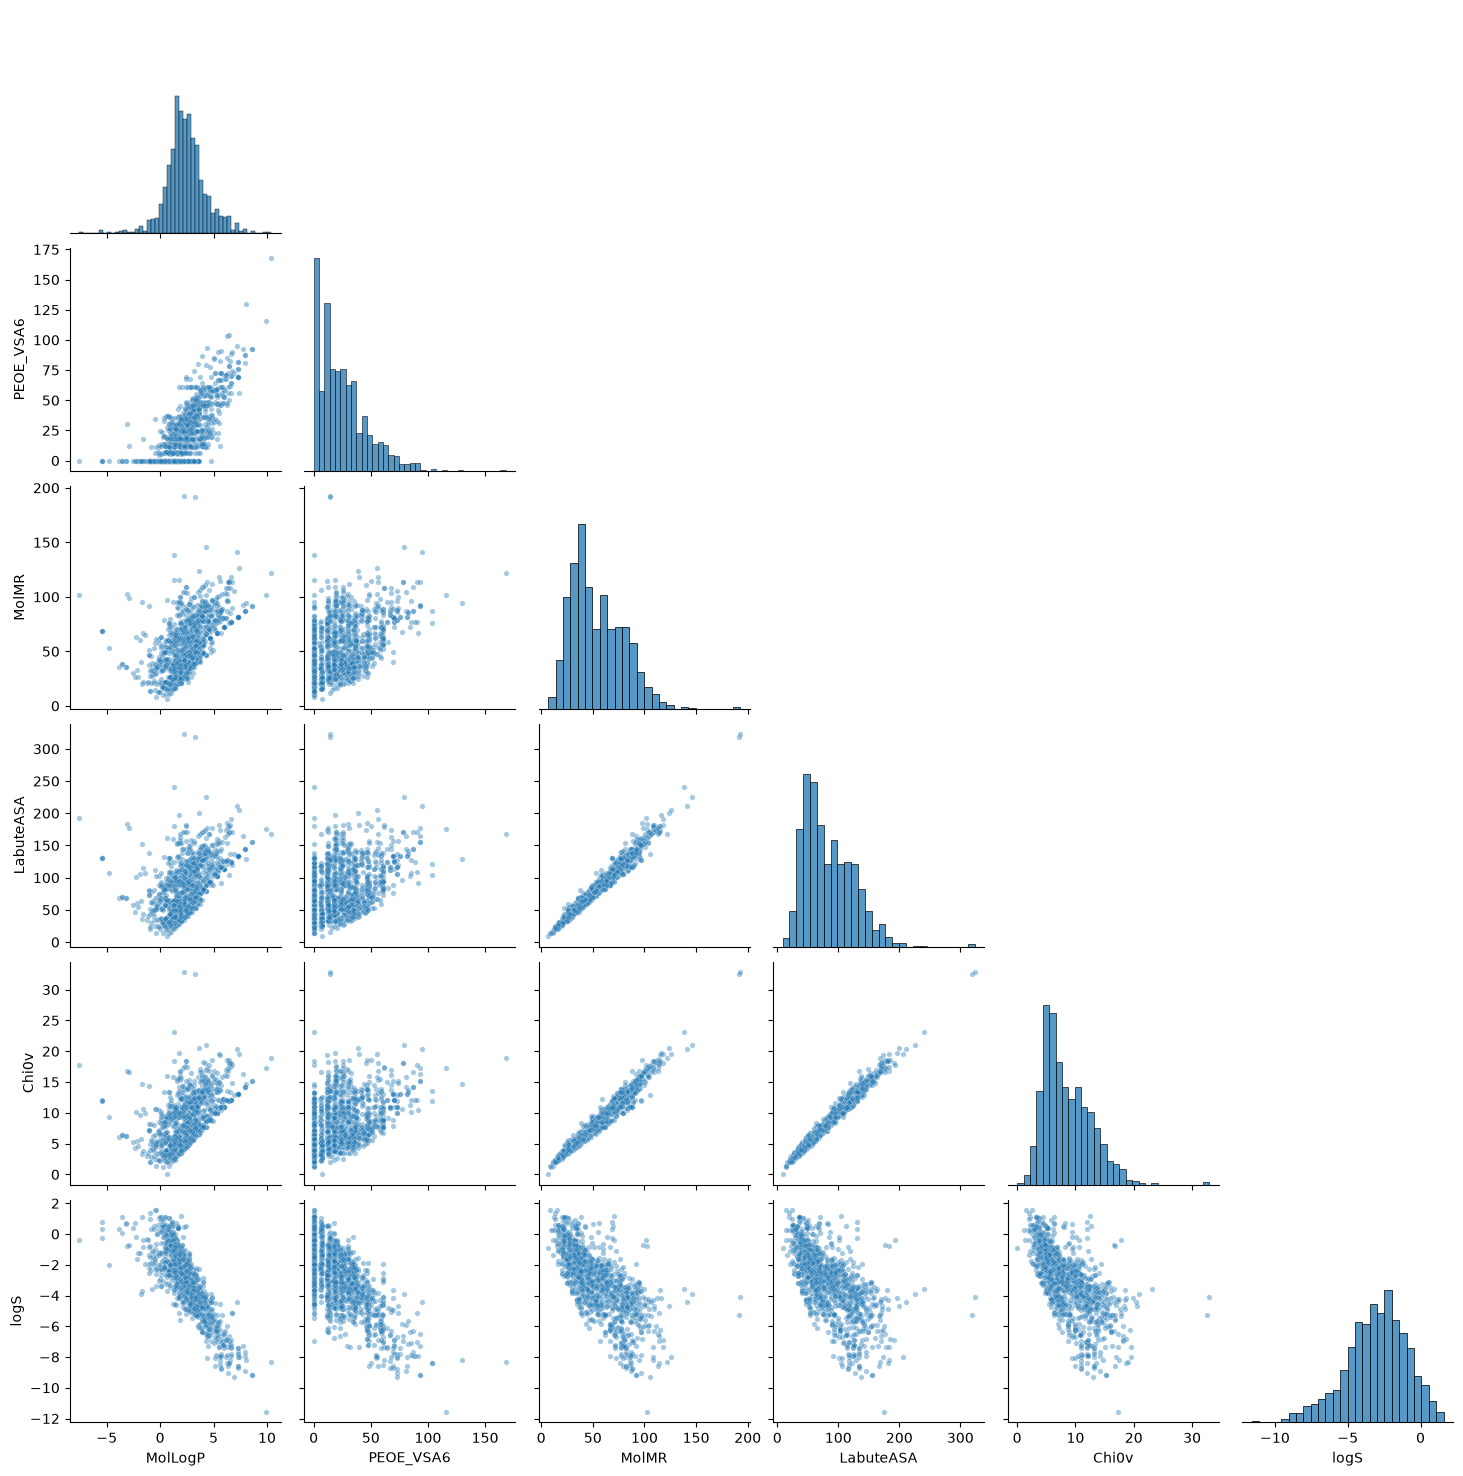

In [154]:
n_top = 5                                          
top_cols = corr.index[:n_top].tolist()

plot_df = desc_df_delaney[top_cols].copy()
plot_df["logS"] = y.values                          
sns.pairplot(plot_df, corner=True, diag_kind="hist",
             plot_kws={"alpha": 0.4, "s": 15})
plt.show()

In [155]:
# using top 30 features from correlation tp target out of 200 descriptors

In [147]:
rf_result(delaney_df, 'logS', desc_df_delaney, 0.2, 42, 200)

c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


['MolLogP', 'PEOE_VSA6', 'MolMR', 'LabuteASA', 'Chi0v', 'HeavyAtomMolWt', 'MolWt', 'ExactMolWt', 'Chi1v', 'FpDensityMorgan1', 'BCUT2D_LOGPHI', 'Chi2v', 'BertzCT', 'Chi1', 'HeavyAtomCount', 'NumAromaticCarbocycles', 'fr_benzene', 'Chi3v', 'Chi0', 'AvgIpc', 'Chi1n', 'Kappa1', 'NumValenceElectrons', 'Chi0n', 'SMR_VSA7', 'SMR_VSA10', 'Chi2n', 'Chi4v', 'RingCount', 'NumAromaticRings']
custom (1144, 15) | y: (1144,)
morgan (1144, 2048) | y: (1144,)
descr (1144, 30) | y: (1144,)


,n_features,Train R2,Test R2,Test RMSE,Test MAE
Feature set,,,,,
Custom fingerprint,15,0.485,0.384,1.638,1.222
Morgan fingerprint,2048,0.943,0.700,1.144,0.856
RDKit descriptors,30,0.984,0.899,0.664,0.484


ecoli dataset

In [148]:
ecoli_cleaned.columns

Index(['chembl_id', 'smiles', 'mic', 'unit'], dtype='str')

,chembl_id,smiles,mic,unit,molecule_image,aromatic_c_O,aliphatic_N,alcohol,benzene,sulphur_ring,...,carboxylic,pyridine,halogen,amide,ketone,aldehyde,alkene,alkyne,fingerprint,morgan_fp
0,CHEMBL1689756,CN(C)[C@@H]1C(O)=C(C(N)=O)C(=O)[C@@]2(O)C(O)=C...,0.25,ug.mL-1,,1,1,1,0,0,...,0,1,1,1,1,0,1,0,"[1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,CHEMBL1222951,CO/N=C1/CCN(c2c(F)cc3c(=O)c(C(=O)O)cn(C4CC4)c3...,8.00,ug.mL-1,,0,1,1,1,0,...,1,1,1,0,1,0,0,0,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CHEMBL2403434,COc1cccc(CC(=O)Nc2nc(-c3ccc(Br)cc3)cs2)c1,12.50,ug.mL-1,,1,1,0,1,0,...,0,0,1,1,0,0,0,0,"[1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C...,0.19,ug.mL-1,,0,1,1,0,0,...,1,0,0,1,0,0,1,0,"[0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0]","[0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,CHEMBL22,COc1cc(Cc2cnc(N)nc2N)cc(OC)c1OC,0.25,ug.mL-1,,1,1,0,1,0,...,0,0,0,0,0,0,0,0,"[1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."

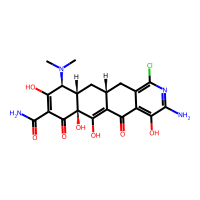
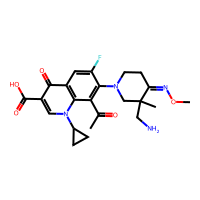
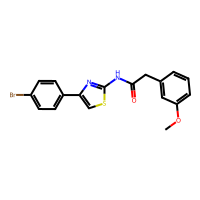
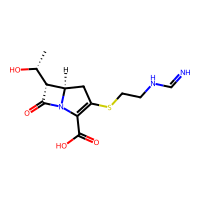
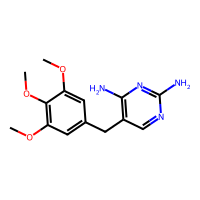

In [149]:
ecoli_cleaned= column_smiles_to_image(ecoli_cleaned, 'smiles', 'molecule_image')
ecoli_cleaned=custom_fp(motifs, ecoli_cleaned, 'smiles')
ecoli_cleaned= morgan_fp(ecoli_cleaned, 'smiles')
ecoli_cleaned.head()

In [150]:
desc_ecoli_cleaned= decriptor_calc(ecoli_cleaned, 'smiles')
desc_ecoli_cleaned.head()

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,13.299498,13.299498,0.034495,-2.691949,0.250126,29.718750,464.862,443.694,464.109877,170,...,0,0,0,0,0,0,0,0,0,0
1,15.611530,15.611530,0.042858,-1.384387,0.502987,22.090909,458.490,431.274,458.196548,176,...,0,0,0,0,0,0,0,0,0,0
2,12.180454,12.180454,0.097260,-0.097260,0.668333,10.416667,403.301,388.181,402.003761,122,...,0,0,0,0,0,1,0,0,0,0
3,11.938415,11.938415,0.052549,-1.104254,0.224452,26.100000,299.352,282.216,299.093977,110,...,1,0,0,0,0,0,0,0,0,0
4,5.848108,5.848108,0.153835,0.153835,0.853356,10.238095,290.323,272.179,290.137890,112,...,0,0,0,0,0,0,0,0,0,0


In [156]:
# choosing important features from the descriptor set based on correlation values with the target
y = ecoli_cleaned["mic"]

# Pearson (linear) and Spearman (monotonic) correlation of each descriptor with the target
corr = pd.DataFrame({
    "pearson":  desc_ecoli_cleaned.corrwith(y, method="pearson"),
    "spearman": desc_ecoli_cleaned.corrwith(y, method="spearman"),
}).dropna()

# Rank by absolute Pearson correlation
corr = corr.reindex(corr["pearson"].abs().sort_values(ascending=False).index)
print(corr.head(15).round(3))

c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


                          pearson  spearman
PEOE_VSA5                   0.064    -0.078
qed                         0.061    -0.041
EState_VSA11                0.060    -0.203
fr_thiazole                 0.050    -0.092
NumRotatableBonds          -0.050    -0.005
Kappa2                     -0.049     0.062
NumAliphaticHeterocycles    0.048    -0.213
PEOE_VSA7                  -0.045     0.158
Kappa3                     -0.043     0.110
Phi                        -0.043     0.059
Kappa1                     -0.042    -0.041
EState_VSA9                -0.041     0.006
PEOE_VSA12                  0.041    -0.037
BCUT2D_LOGPHI               0.040    -0.155
EState_VSA8                -0.040     0.103


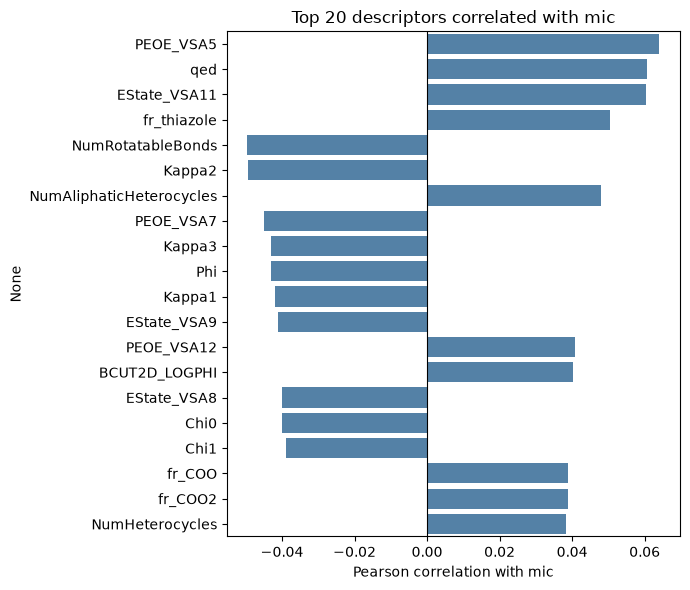

In [157]:
top = corr.head(20)
plt.figure(figsize=(7, 6))
sns.barplot(x=top["pearson"], y=top.index, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with mic")
plt.title("Top 20 descriptors correlated with mic")
plt.tight_layout()
plt.show()

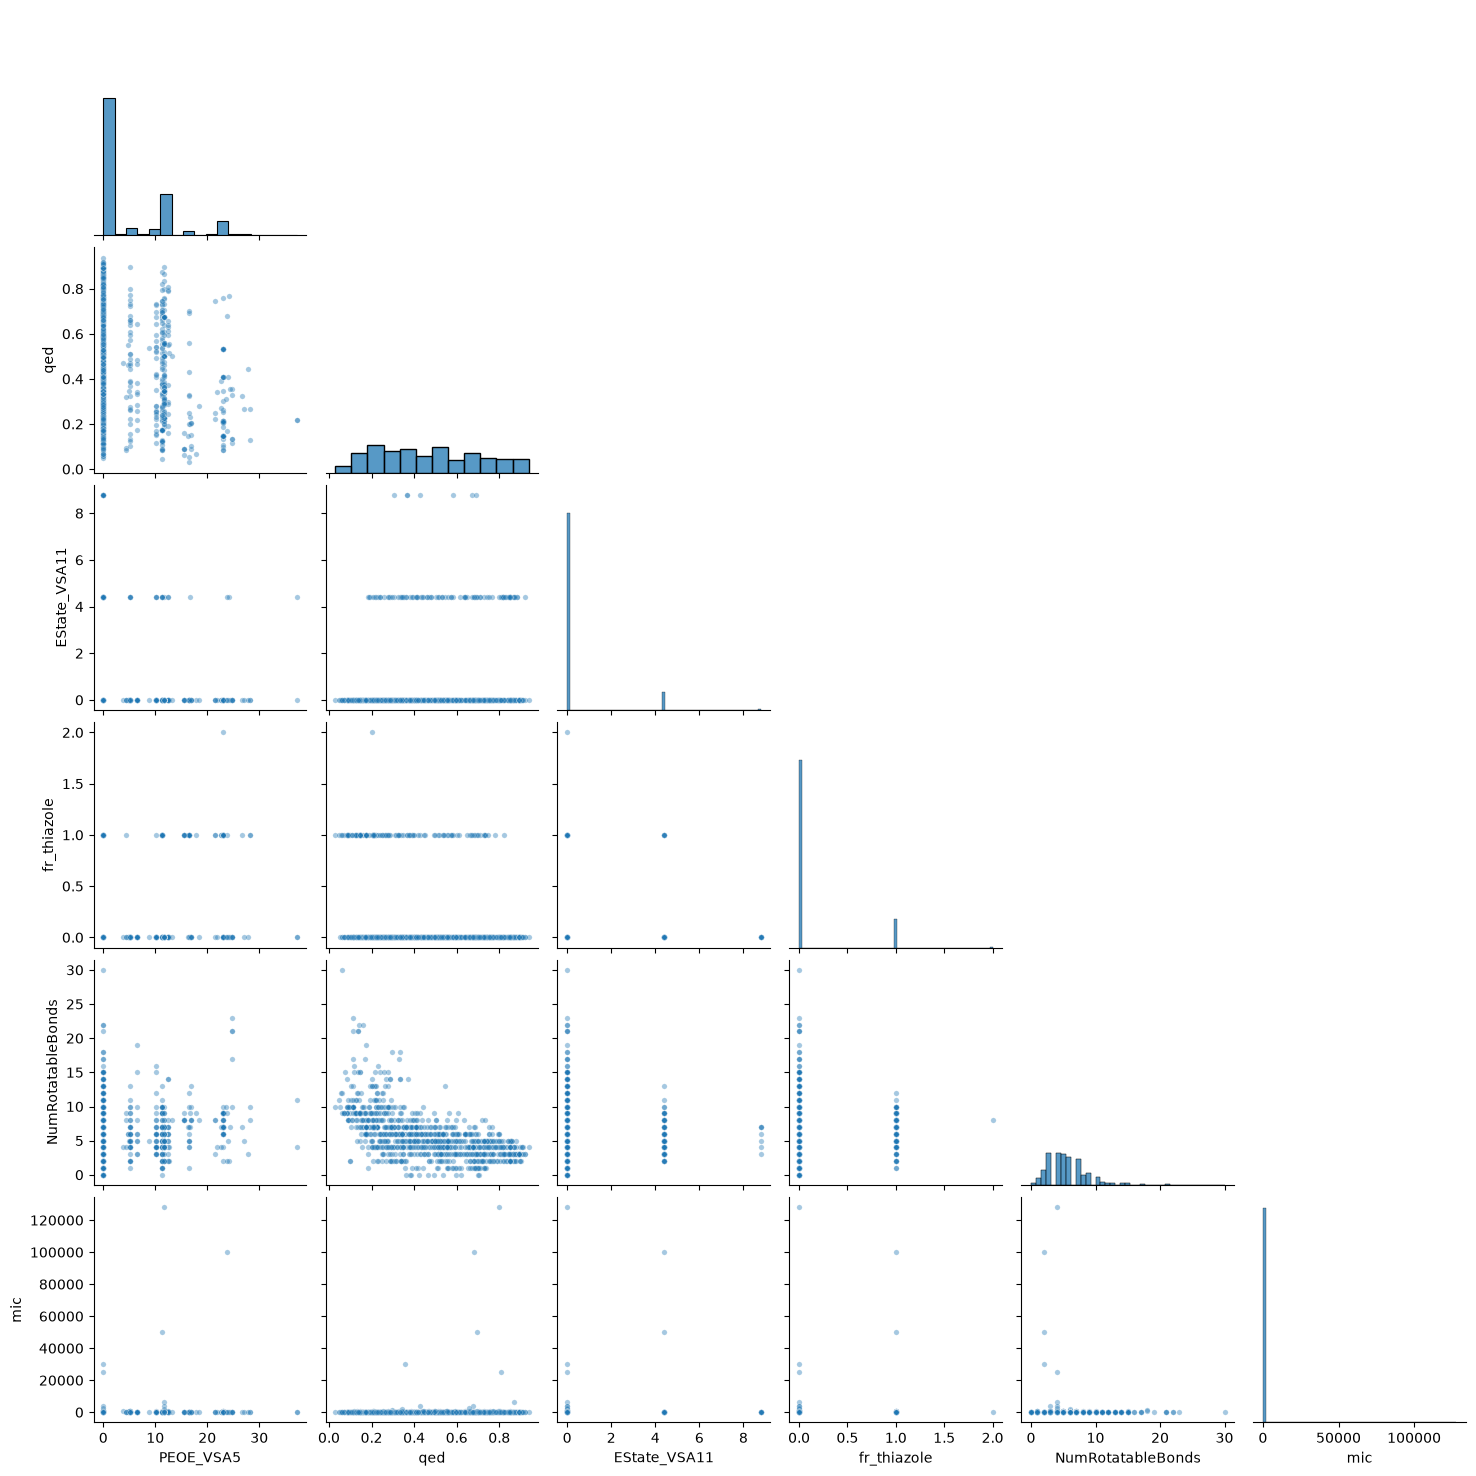

In [158]:
n_top = 5                                          
top_cols = corr.index[:n_top].tolist()

plot_df = desc_ecoli_cleaned[top_cols].copy()
plot_df["mic"] = y.values                          
sns.pairplot(plot_df, corner=True, diag_kind="hist",
             plot_kws={"alpha": 0.4, "s": 15})
plt.show()

In [151]:
rf_result(ecoli_cleaned, 'mic', desc_ecoli_cleaned, 0.2, 42, 200)

c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bharg\anaconda3\envs\UZH\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


['PEOE_VSA5', 'qed', 'BalabanJ', 'Chi0', 'PEOE_VSA12', 'Chi1', 'EState_VSA11', 'NumAliphaticHeterocycles', 'Kappa2', 'HeavyAtomCount', 'Chi0n', 'fr_Ndealkylation1', 'Kappa1', 'Chi1n', 'NumValenceElectrons', 'fr_piperzine', 'NumSaturatedHeterocycles', 'PEOE_VSA7', 'LabuteASA', 'EState_VSA9', 'NumRotatableBonds', 'MolMR', 'fr_COO2', 'fr_COO', 'Chi1v', 'ExactMolWt', 'MolWt', 'Chi0v', 'HeavyAtomMolWt', 'fr_lactam']
custom (1098, 15) | y: (1098,)
morgan (1098, 2048) | y: (1098,)
descr (1098, 30) | y: (1098,)


,n_features,Train R2,Test R2,Test RMSE,Test MAE
Feature set,,,,,
Custom fingerprint,15,0.10,-0.220,4320.756,776.531
Morgan fingerprint,2048,0.84,0.521,2706.658,543.477
RDKit descriptors,30,0.84,-1.400,6060.322,1222.278
